# Tema 12 · Máquinas de vectores de soporte

La frontera con el mayor margen posible, y los kernels para fronteras curvas.

Este cuaderno es el tema 12 de la [ruta de aprendizaje de la OBIA](https://iabolivia.org/ruta/): la teoría y los ejercicios de [la página del tema](https://iabolivia.org/ruta/12-maquinas-de-vectores-de-soporte/), con todo su código. Ejecuta las celdas en orden, de arriba abajo (o *Entorno de ejecución → Ejecutar todas*).

Debajo de cada celda está la salida que dio cuando se escribió el tema. Al ejecutarla, la tuya puede variar en los últimos decimales. Las actividades interactivas están en la página del tema.

# Teoría

## La pregunta

Imagina un mapa con dos barrios, uno a cada lado de un terreno vacío, y que te piden trazar una carretera recta que los separe. Hay muchísimas rectas que dejan cada barrio de su lado. Pero algunas pasan rozando las casas de un barrio, y otras van por el medio, lejos de los dos. ¿Cuál elegirías?

Seguramente la del medio, con la **calle más ancha posible**. Si mañana se construye una casa nueva cerca del borde de su barrio, esa recta todavía la deja del lado correcto; la que pasaba rozando, no. Esa intuición es todo el método de este tema: las **máquinas de vectores de soporte** (*support vector machines*, SVM) eligen, entre todas las fronteras que separan las clases, la que deja el **margen** más grande.

En este tema vas a:

- explicar qué son el **margen** y los **vectores de soporte**, y por qué unos pocos puntos deciden toda la frontera;
- explicar el papel del hiperparámetro **C** (el **margen suave**) y su relación con el sobreajuste;
- programar una SVM lineal desde cero con el **descenso de subgradiente** sobre la **pérdida bisagra**;
- explicar el **truco del kernel** con un ejemplo de levantar los datos a 3D;
- ajustar **C** y **gamma** del kernel RBF con validación cruzada.

Necesitas lo del tema 8 (la frontera lineal *z* = 0 y la entropía cruzada), el descenso de gradiente del tema 6 y lo del tema 10 sobre escalar, *pipelines* y `GridSearchCV`.

## Actividad: el camino más ancho

Hay puntos de dos clases: círculos tinta y cuadrados coral, como en el tema 8. La recta gruesa es la frontera que elige una SVM y la franja sombreada es la **calle**: el camino más ancho que se puede abrir entre las dos clases. Los puntos con un anillo alrededor son los **vectores de soporte**. La computadora recalcula la frontera cada vez que mueves algo.

> **Actividad interactiva:** está en la [página del tema](https://iabolivia.org/ruta/12-maquinas-de-vectores-de-soporte/teoria/). Ábrela en el navegador para usarla.
Prueba esto, en orden:

1. Arrastra un punto que esté lejos de la calle, sin anillo. ¿Se mueve la frontera?
2. Ahora arrastra un punto con anillo hacia la otra clase. ¿Qué le pasa a la calle?
3. Hay un círculo tinta metido entre los cuadrados coral: es un **atípico**. Con *C* alto (*C* es una perilla que explicamos más abajo: cuánto cuesta cada punto mal ubicado), ¿cómo queda la calle? Baja *C* poco a poco y mira qué pasa con el ancho y con ese punto.
4. Con *C* muy bajo, cuenta los anillos. ¿Por qué hay tantos ahora?

Lo que acabas de ver es la idea central: **solo unos pocos puntos definen la frontera**. Los que están lejos de la calle no cuentan; los que la tocan (o se meten en ella) la sostienen, como los soportes de un puente. Y *C* decide cuánto pesan los puntos que se meten en la calle o quedan del lado equivocado.

## Muchas rectas separan, ¿cuál elegir?

Empecemos con datos **sintéticos**: dos grupos de 20 puntos que se pueden separar con una recta. Para las SVM es costumbre escribir las clases como **−1 y +1** en lugar de 0 y 1, porque así el signo dice la clase. La variable `signo` guarda esas etiquetas.

Clases como 0 y 1:   [0 1 0 0 1 0 1 1]
Clases como signos:  [-1  1 -1 -1  1 -1  1  1]


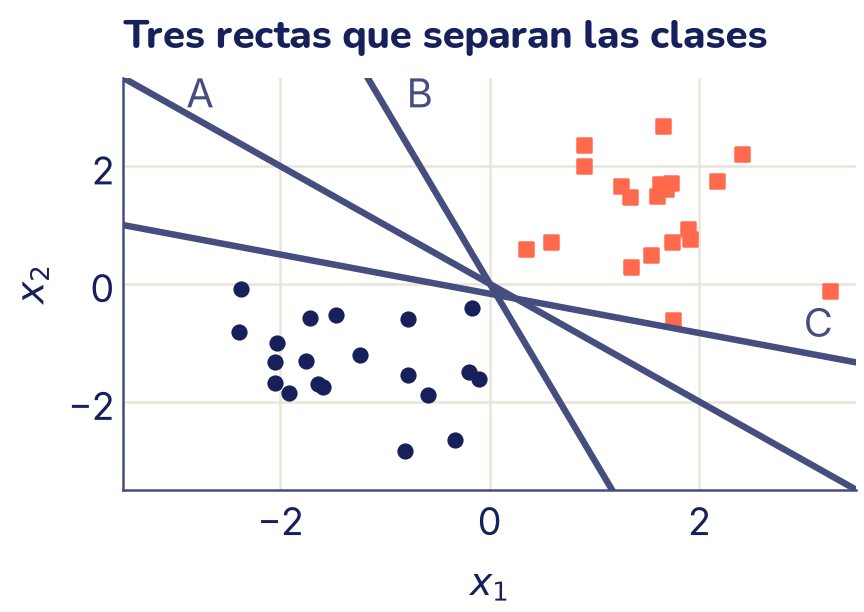

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs

# 40 puntos sintéticos en dos grupos, 20 de cada clase
X, y = make_blobs(n_samples=40, centers=[[-1.5, -1], [1.5, 1]],
                  cluster_std=0.8, random_state=1)
# Las SVM usan las clases -1 y +1 en lugar de 0 y 1
signo = np.where(y == 1, 1, -1)
print("Clases como 0 y 1:  ", y[:8])
print("Clases como signos: ", signo[:8])

def dibujar_clases(X, y, ax=None, s=30):
    """Clase 0: círculos de color C0. Clase 1: cuadrados de color C1."""
    ax = ax or plt.gca()
    ax.scatter(X[y == 0, 0], X[y == 0, 1], s=s, color="C0",
               marker="o", label="Clase 0")
    ax.scatter(X[y == 1, 0], X[y == 1, 1], s=s, color="C1",
               marker="s", label="Clase 1")

# Tres rectas w1·x1 + w2·x2 + b = 0: nombre, (w1, w2), b
# y dónde escribir el nombre en el dibujo
rectas = [("A", (1, 1), 0, (-2.9, 3)),
          ("B", (3, 1), 0, (-0.8, 3)),
          ("C", (1, 3), 0.5, (3, -0.9))]
x1 = np.array([-4, 4])
dibujar_clases(X, y)
for nombre, (w1, w2), b, (tx, ty) in rectas:
    # Despejamos x2 de la ecuación de la recta
    plt.plot(x1, -(w1 * x1 + b) / w2, color="C2")
    plt.text(tx, ty, nombre, color="C2", fontsize=16)
plt.xlim(-3.5, 3.5)
plt.ylim(-3.5, 3.5)
plt.xlabel("$x_1$")
plt.ylabel("$x_2$")
plt.title("Tres rectas que separan las clases")
plt.show()

Las tres rectas aciertan con los 40 puntos, así que la tasa de aciertos no sirve para elegir. Lo que cambia es **qué tan cerca pasan de los puntos**. Como en el tema 8, cada recta da un **puntaje** a cada punto:

$$z = {w}_{1} {x}_{1} + {w}_{2} {x}_{2} + b$$

La recta es donde *z* = 0; de un lado *z* es positivo (se predice +1) y del otro, negativo (se predice −1). El puntaje solo no es una distancia: si multiplicas *w*₁, *w*₂ y *b* por 10, la recta es la misma, pero los puntajes se multiplican por 10. Para obtener la **distancia** de un punto a la recta, se divide el puntaje (sin signo) por el largo del vector de pesos, ‖*w*‖:

$$\text{distancia} = \frac{| z |}{\| \mathbf{w} \|}$$

donde

$$\| \mathbf{w} \| = \sqrt{{w}_{1}^{2} + {w}_{2}^{2}}$$

¿Por qué dividir? Porque así se deshace la escala. Un ejemplo: con *w* = (3, 4) y *b* = 0, la recta 3*x*₁ + 4*x*₂ = 0 pasa por el origen, y el punto (3, 4) está justo en la dirección de *w*, así que su distancia a la recta es lo que mide del origen al punto: √(3² + 4²) = 5. Su puntaje es *z* = 3·3 + 4·4 = 25 y ‖*w*‖ = √(9 + 16) = 5, así que la fórmula da 25/5 = 5. Si multiplicamos todo por 10, *w* = (30, 40): el puntaje sube a 250, pero ‖*w*‖ también sube a 50, y la distancia sigue siendo 250/50 = 5.

Midamos, para cada recta, la distancia al punto más cercano:

In [ ]:
def distancias(X, w, b):
    """Distancia de cada fila de X a la recta w·x + b = 0."""
    return np.abs(X @ w + b) / np.linalg.norm(w)

for nombre, (w1, w2), b, _ in rectas:
    w = np.array([w1, w2])
    aciertos = np.mean(np.sign(X @ w + b) == signo)
    cerca = distancias(X, w, b).min()
    print(f"Recta {nombre}, w = ({w1}, {w2}), b = {b}:  aciertos"
          f" {aciertos:.0%}   punto más cercano a {cerca:.2f}")

Recta A, w = (1, 1), b = 0:  aciertos 100%   punto más cercano a 0.41
Recta B, w = (3, 1), b = 0:  aciertos 100%   punto más cercano a 0.29
Recta C, w = (1, 3), b = 0.5:  aciertos 100%   punto más cercano a 0.13


La recta A deja más espacio libre a cada lado que las otras dos: su punto más cercano está a 0,41, mientras que C pasa a 0,13 de un punto. Esa distancia al punto más cercano se llama **margen**, y la SVM busca la recta con el margen más grande posible.

## El margen y la calle

Como podemos escalar *w* y *b* sin mover la recta, la SVM fija la escala con una convención: los puntos más cercanos tienen puntaje exactamente +1 o −1. Las rectas *z* = +1 y *z* = −1 son entonces los **bordes de la calle**, y ningún punto bien ubicado queda entre ellas. Con la fórmula de la distancia, cada borde está a 1/‖*w*‖ de la frontera, así que

$$\text{ancho de la calle} = \frac{2}{\| \mathbf{w} \|}$$

Una calle ancha significa pesos **chicos**. Ahora fíjate en el producto *y*·*z*, la clase (−1 o +1) por el puntaje: es positivo cuando el punto está del lado correcto y vale 1 o más cuando además está fuera de la calle. Encontrar la calle más ancha que deja todos los puntos fuera de ella es entonces resolver

$$\text{minimizar}_{\mathbf{w} , b} \quad \frac{1}{2} {\| \mathbf{w} \|}^{2} \qquad \text{con} \quad {y}_{i} {z}_{i} \ge 1 \quad \text{para todo} \quad i$$

(minimizar ‖*w*‖ o su cuadrado da lo mismo; el cuadrado y el ½ solo hacen más fácil la derivada). Esto se llama **margen duro**: no se permite ningún punto dentro de la calle.

Los puntos que quedan justo sobre los bordes de la calle son los **vectores de soporte** (cada punto es un vector de dos números, y estos «sostienen» la calle). Si mueves cualquier otro punto sin meterlo en la calle, la solución no cambia: los demás ni siquiera aparecen en la respuesta. Es lo que viste en la actividad.

## La pérdida bisagra

El margen duro tiene dos problemas. Si las clases no se pueden separar con una recta, no hay solución. Y aunque se puedan separar, un solo punto raro puede obligar a una calle angostísima. Para tolerar algunos puntos dentro de la calle, o incluso del lado equivocado, la SVM les cobra una multa con la **pérdida bisagra** (en inglés, *hinge*):

$$ℓ = \mathrm{max} ( 0 , \; 1 - y \cdot z )$$

Se lee así: si el punto está del lado correcto y fuera de la calle (*y*·*z* ≥ 1), no paga nada. Si se mete en la calle, paga lo que le falta para llegar al borde, y si cruza al lado equivocado paga todavía más, en línea recta. Comparémosla con la entropía cruzada del tema 8, escrita con las clases −1 y +1 (es la misma fórmula, −log *p* de la clase correcta: como *p* = σ(*y*·*z*) = 1/(1 + *e*^(−*y*·*z*)), queda −log σ(*y*·*z*) = log(1 + *e*^(−*y*·*z*)); `np.log` es el logaritmo natural, ln):

y·z =   -1:  bisagra 2.00   entropía cruzada 1.31
y·z =    0:  bisagra 1.00   entropía cruzada 0.69
y·z =  0.5:  bisagra 0.50   entropía cruzada 0.47
y·z =    1:  bisagra 0.00   entropía cruzada 0.31
y·z =    2:  bisagra 0.00   entropía cruzada 0.13
y·z =    3:  bisagra 0.00   entropía cruzada 0.05


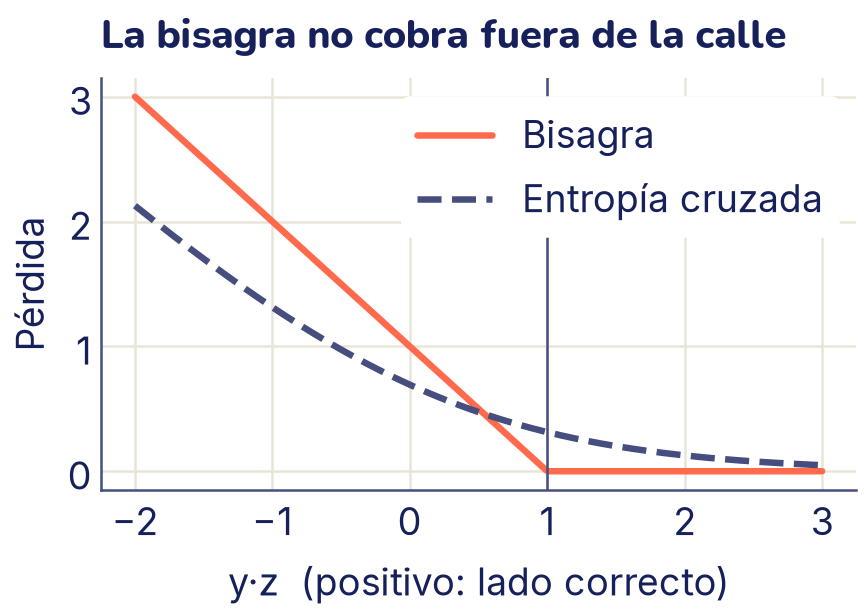

In [ ]:
yz = np.linspace(-2, 3, 300)          # la clase por el puntaje
bisagra = np.maximum(0, 1 - yz)
entropia = np.log(1 + np.exp(-yz))

for valor in [-1, 0, 0.5, 1, 2, 3]:
    print(f"y·z = {valor:4}:  bisagra {max(0, 1 - valor):.2f}"
          f"   entropía cruzada {np.log(1 + np.exp(-valor)):.2f}")

plt.plot(yz, bisagra, color="C1", linewidth=2.6, label="Bisagra")
plt.plot(yz, entropia, color="C2", linestyle="--",
         label="Entropía cruzada")
plt.axvline(1, color="C2", linewidth=1)
plt.xlabel("y·z  (positivo: lado correcto)")
plt.ylabel("Pérdida")
plt.title("La bisagra no cobra fuera de la calle")
# Con fondo blanco, la línea vertical no cruza el texto de la leyenda
plt.legend(frameon=True)
plt.show()

Las dos se parecen para los puntos mal clasificados: crecen casi en línea recta. La diferencia está a la derecha. La entropía cruzada **nunca llega a cero**: aunque un punto esté lejísimos y bien clasificado, todavía empuja un poquito los pesos. La bisagra es **exactamente cero** desde *y*·*z* = 1. Por eso en una SVM los puntos bien ubicados fuera de la calle no influyen en nada, y solo los vectores de soporte deciden la frontera. La esquina en *y*·*z* = 1 es la que le da el nombre: se dobla como una bisagra.

## Margen suave: lo que pesa C

Juntamos las dos ideas en una sola función a minimizar: queremos una calle ancha (pesos chicos) y pocas multas.

$$J ( \mathbf{w} , b ) = \frac{1}{2} {\| \mathbf{w} \|}^{2} + C \sum_{i = 1}^{n} \mathrm{max} ( 0 , \; 1 - {y}_{i} {z}_{i} )$$

Esto se llama **margen suave**. El número **C** es un hiperparámetro que decide cuánto vale cada multa frente al ancho de la calle:

- Con **C grande**, las multas son carísimas: la SVM prefiere una calle angosta antes que dejar un punto adentro. Se parece al margen duro y persigue cada punto, aunque sea ruido. Es el camino al **sobreajuste**.
- Con **C chico**, las multas son baratas: la SVM abre una calle ancha y acepta que algunos puntos se metan o queden del lado equivocado. Si *C* es demasiado chico, ignora hasta lo que importa: **subajuste**.

Si lo comparas con la regularización del tema 7, el término ½‖*w*‖² hace el papel de la penalización de Ridge, y *C* es su inverso: más *C*, menos regularización. Es el mismo `C` que viste en `LogisticRegression`.

## Programar la SVM desde cero

Para minimizar *J* usamos el descenso de gradiente del tema 6. Hay un detalle: la bisagra tiene una esquina en *y*·*z* = 1, y en una esquina la derivada no existe (la pendiente es −1 de un lado y 0 del otro). La solución es elegir una de las dos pendientes y seguir: eso se llama un **subgradiente**, y bajar con él es el **descenso de subgradiente**. En la práctica casi ningún punto cae justo en la esquina, así que basta decidir qué hacer en ese caso.

Para cada punto, la derivada de su multa es:

- si *y*ᵢ·*z*ᵢ ≥ 1 (fuera de la calle, del lado correcto): **0**, porque no paga nada;
- si *y*ᵢ·*z*ᵢ menor que 1: la multa es 1 − *y*ᵢ·(*w*₁*x*ᵢ₁ + *w*₂*x*ᵢ₂ + *b*). Derivando con respecto a cada peso por separado, como en el tema 5, queda −*y*ᵢ·*x*ᵢ₁ respecto de *w*₁, −*y*ᵢ·*x*ᵢ₂ respecto de *w*₂ y −*y*ᵢ respecto de *b*. Las dos primeras se escriben juntas como un vector, −*y*ᵢ·*x*ᵢ: es la «derivada respecto de *w*», una derivada por cada peso.

Sumando la derivada de ½‖*w*‖², que es el mismo *w*:

$$\frac{\partial J}{\partial \mathbf{w}} = \mathbf{w} - C \sum_{{y}_{i} {z}_{i} < 1} {y}_{i} {\mathbf{x}}_{i} \qquad \frac{\partial J}{\partial b} = - C \sum_{{y}_{i} {z}_{i} < 1} {y}_{i}$$

Las sumas recorren solo los puntos que pagan multa. Se leen con sentido común: cada punto que se mete en la calle empuja los pesos para quedar más de su lado, y el primer término, *w*, tira de los pesos hacia cero para ensanchar la calle. El paso es el de siempre:

$$\mathbf{w} \leftarrow \mathbf{w} - \alpha \cdot \frac{\partial J}{\partial \mathbf{w}} \qquad b \leftarrow b - \alpha \cdot \frac{\partial J}{\partial b}$$

In [ ]:
def objetivo(X, signo, w, b, C):
    """J = ½‖w‖² + C · (suma de las pérdidas bisagra)."""
    multas = np.maximum(0, 1 - signo * (X @ w + b))
    return 0.5 * w @ w + C * multas.sum()

def svm_subgradiente(X, signo, C, tasa, pasos):
    """SVM lineal con descenso de subgradiente.

    Devuelve los pesos w, el término independiente b y el objetivo J
    antes de cada paso.
    """
    n, d = X.shape
    w = np.zeros(d)                   # un peso por característica
    b = 0.0
    historial = []
    for paso in range(pasos):
        historial.append(objetivo(X, signo, w, b, C))
        yz = signo * (X @ w + b)      # la clase por el puntaje
        multa = yz < 1                # los que se meten en la calle
        # X[multa].T @ signo[multa] es la suma de signo[i] * X[i]
        # sobre los puntos que pagan multa (.T es la transpuesta)
        dw = w - C * X[multa].T @ signo[multa]
        db = -C * signo[multa].sum()
        w = w - tasa * dw             # un paso en contra
        b = b - tasa * db
    return w, b, np.array(historial)

w_svm, b_svm, historial = svm_subgradiente(X, signo, C=1, tasa=0.001,
                                           pasos=20000)
for paso in [0, 10, 100, 1000, 19999]:
    print(f"Paso {paso:5d}:   J = {historial[paso]:.4f}")
print("w =", np.round(w_svm, 3), "  b =", round(b_svm, 3))

Paso     0:   J = 40.0000
Paso    10:   J = 4.6549
Paso   100:   J = 1.5627
Paso  1000:   J = 1.4176
Paso 19999:   J = 1.4069
w = [0.798 0.923]   b = 0.173


Al empezar, con *w* = 0 y *b* = 0, todos los puntos tienen *z* = 0 y pagan una multa de 1: *J* vale 40. Baja muy rápido y después se estabiliza. Comparemos con `SVC` de scikit-learn, el clasificador de vectores de soporte, con un kernel lineal (en un rato vas a ver qué es un kernel) y el mismo *C*:

In [ ]:
from sklearn.svm import SVC

svm = SVC(kernel="linear", C=1).fit(X, y)
print("scikit-learn:   w =", np.round(svm.coef_[0], 3),
      "  b =", np.round(svm.intercept_[0], 3))
print(f"Ancho de la calle: {2 / np.linalg.norm(w_svm):.2f}")

# Vectores de soporte: los que tocan la calle o se meten en ella
yz = signo * (X @ w_svm + b_svm)
nuestros = np.flatnonzero(yz < 1.01)
print("Vectores de soporte (nuestro):     ", nuestros)
print("Vectores de soporte (scikit-learn):", np.sort(svm.support_))
print("Su y·z:", np.round(yz[nuestros], 2))

scikit-learn:   w = [0.797 0.925]   b = 0.174
Ancho de la calle: 1.64
Vectores de soporte (nuestro):      [ 8 11 29 35]
Vectores de soporte (scikit-learn): [ 8 11 29 35]
Su y·z: [1.   1.   1.   0.34]


Los mismos pesos, salvo en la tercera cifra decimal, y los mismos cuatro vectores de soporte de 40 puntos. Tres tienen *y*·*z* = 1: están justo sobre los bordes de la calle. El cuarto tiene *y*·*z* = 0,34: está del lado correcto, pero dentro de la calle, y paga una multa de 0,66. Con *C* = 1, a la SVM le convino aceptar esa multa a cambio de una calle más ancha. (Usamos `yz < 1.01` y no `yz <= 1` porque el descenso no llega exactamente al mínimo: los puntos del borde quedan en 0,999 o 1,002.)

Dibujemos la calle:

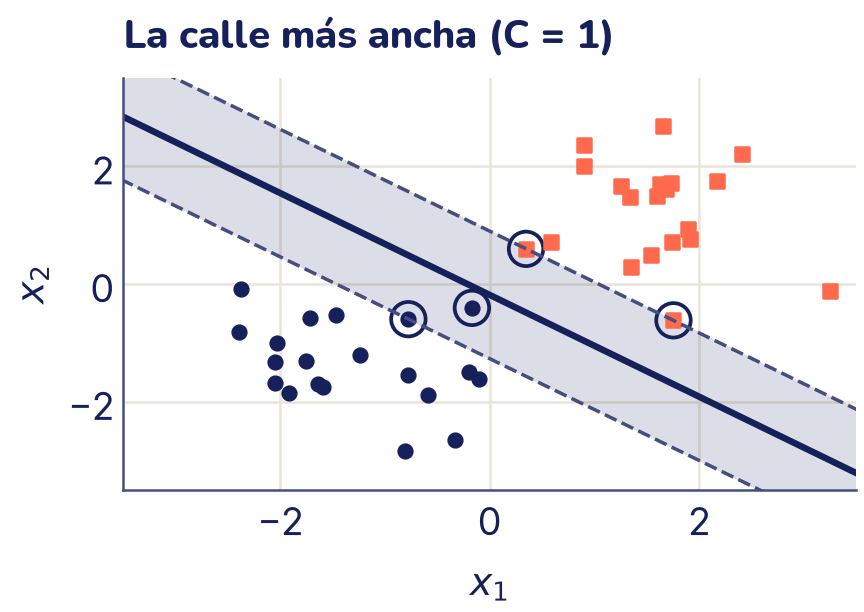

In [ ]:
def dibujar_svm(w, b, ax=None, vectores=None):
    """La frontera (z = 0), los bordes (z = -1 y z = 1) y la calle."""
    ax = ax or plt.gca()
    A, B = np.meshgrid(np.linspace(-4, 4, 300), np.linspace(-4, 4, 300))
    Z = w[0] * A + w[1] * B + b
    ax.contourf(A, B, Z, levels=[-1, 1], colors=["C2"], alpha=0.18)
    ax.contour(A, B, Z, levels=[-1, 0, 1], colors=["C2", "C0", "C2"],
               linestyles=["--", "-", "--"], linewidths=[1.4, 2.6, 1.4])
    if vectores is not None:
        # Un anillo alrededor de cada vector de soporte
        ax.scatter(vectores[:, 0], vectores[:, 1], s=190,
                   facecolors="none", edgecolors="C0", linewidths=1.5)
    ax.set_xlim(-3.5, 3.5)
    ax.set_ylim(-3.5, 3.5)

dibujar_svm(w_svm, b_svm, vectores=X[nuestros])
dibujar_clases(X, y)
plt.xlabel("$x_1$")
plt.ylabel("$x_2$")
plt.title("La calle más ancha (C = 1)")
plt.show()

Si borraras cualquiera de los 36 puntos sin anillo y volvieras a entrenar, la recta sería exactamente la misma. Lo vas a comprobar en el ejercicio 1.

## C: cuánto manda un atípico

Agreguemos a los datos un punto **atípico**: un círculo de la clase 0 metido en la zona de los cuadrados. Las clases todavía se pueden separar con una recta, pero muy forzada. Entrenamos con cuatro valores de *C*. Desde aquí usamos `SVC`, que ya comprobamos que da lo mismo que nuestro código.

C =  0.01:  ancho 4.67   vectores de soporte 28   el atípico va a la clase 1
C =   0.1:  ancho 2.56   vectores de soporte 10   el atípico va a la clase 1
C =     1:  ancho 1.85   vectores de soporte  5   el atípico va a la clase 1
C =   100:  ancho 0.19   vectores de soporte  3   el atípico va a la clase 0


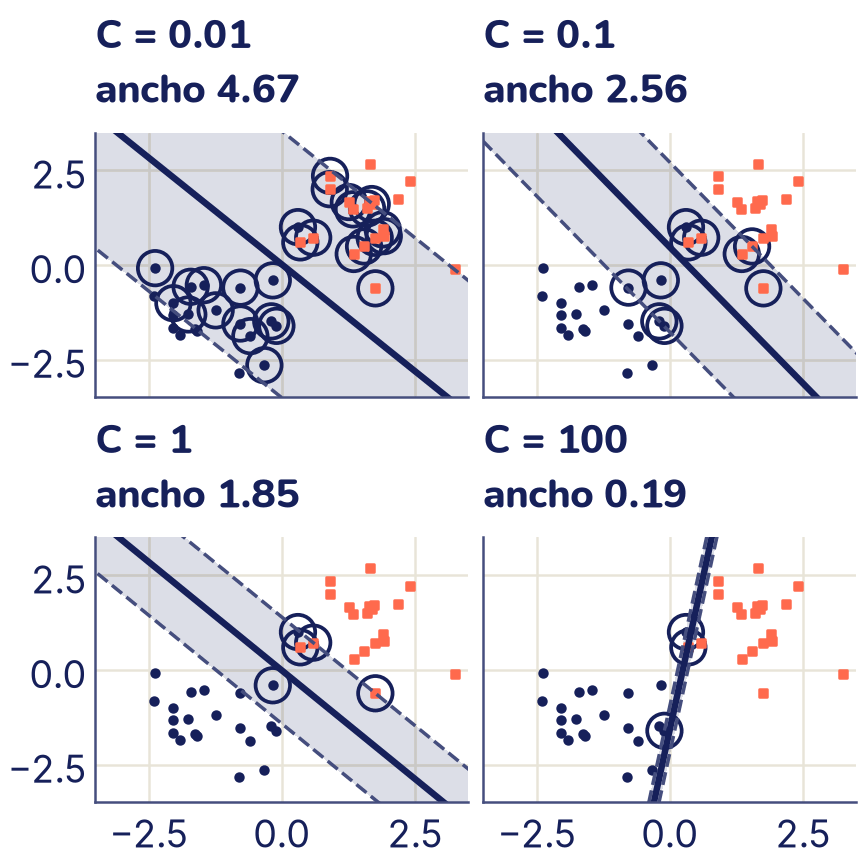

In [ ]:
# Un círculo de la clase 0 metido en la zona de la clase 1
X_atip = np.vstack([X, [[0.3, 1.0]]])
y_atip = np.append(y, 0)

fig, ejes = plt.subplots(2, 2, figsize=(4.8, 4.8),
                         sharex=True, sharey=True)
for eje, C in zip(ejes.flat, [0.01, 0.1, 1, 100]):
    modelo = SVC(kernel="linear", C=C).fit(X_atip, y_atip)
    w, b = modelo.coef_[0], modelo.intercept_[0]
    ancho = 2 / np.linalg.norm(w)
    dibujar_svm(w, b, ax=eje, vectores=modelo.support_vectors_)
    dibujar_clases(X_atip, y_atip, ax=eje, s=10)
    eje.set_title(f"C = {C}\nancho {ancho:.2f}")
    print(f"C = {C:5}:  ancho {ancho:.2f}"
          f"   vectores de soporte {len(modelo.support_):2d}"
          f"   el atípico va a la clase {modelo.predict([[0.3, 1.0]])[0]}")
plt.show()

Léelo de abajo hacia arriba:

- Con ***C* = 100**, una multa es carísima, así que la SVM gira la frontera hasta dejar al atípico de su lado, con una calle de 0,19 de ancho. Acierta con todos los puntos de entrenamiento, pero esa recta casi vertical no describe los dos grupos: un solo punto, quizá un error al anotar los datos, decidió todo. Es **sobreajuste**.
- Con ***C* = 1** o **0,1**, la SVM acepta perder al atípico (lo clasifica como clase 1) y a cambio abre una calle diagonal y ancha que sigue la forma de los dos grupos.
- Con ***C* = 0,01**, la calle es tan ancha que 28 de los 41 puntos quedan dentro o sobre sus bordes: son vectores de soporte. La frontera ya casi no depende de ningún punto en particular; si *C* bajara todavía más, dejaría de separar bien. Es el lado del **subajuste**.

Cuando *C* baja, **más puntos** son vectores de soporte: la frontera se decide entre muchos, y ninguno manda solo. Es lo que viste con el deslizador de la actividad. El mejor *C* no se adivina: se busca con validación cruzada, como cualquier hiperparámetro.

## Escalar es obligatorio

La SVM mide distancias: el ancho de la calle y el puntaje dependen de los números de cada característica. Si una va de 0 a 1 y otra de 0 a 1000, la segunda decide sola, como pasaba con k-NN en el tema 8. Probémoslo con el conjunto de datos **vinos** (`load_wine`, incluido en scikit-learn): 178 vinos de tres productores, con 13 medidas químicas en escalas muy distintas (la prolina varía en más de 1400 unidades; el tono del color, en poco más de 1). `SVC` maneja tres clases por su cuenta, entrenando una SVM por cada par de clases.

In [ ]:
from sklearn.datasets import load_wine
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

X_vino, y_vino = load_wine(return_X_y=True)
# Columna 12: prolina. Columna 10: tono del color
print(f"La prolina varía en {np.ptp(X_vino[:, 12]):.0f};"
      f" el tono, en {np.ptp(X_vino[:, 10]):.2f}")

sin_escalar = cross_val_score(SVC(), X_vino, y_vino, cv=5).mean()
escalado = cross_val_score(make_pipeline(StandardScaler(), SVC()),
                           X_vino, y_vino, cv=5).mean()
print(f"Exactitud sin escalar: {sin_escalar:.3f}")
print(f"Exactitud estandarizando: {escalado:.3f}")

La prolina varía en 1402; el tono, en 1.23
Exactitud sin escalar: 0.663
Exactitud estandarizando: 0.983


De 0,66 a 0,98 con una sola línea. Como en el tema 10, el escalador va **dentro** del *pipeline*, para que en cada pliegue de la validación cruzada aprenda la media y la desviación solo con los datos de entrenamiento.

## Fronteras curvas: el truco del kernel

Una recta no alcanza para todo. `make_circles` genera dos clases sintéticas en forma de anillos, una dentro de la otra: ninguna recta las separa. Pero mira lo que pasa si a cada punto le agregamos una tercera coordenada, su distancia al cuadrado al centro:

$${x}_{3} = {x}_{1}^{2} + {x}_{2}^{2}$$

Recta en el plano:     aciertos 0.50
Plano en 3D:           aciertos 1.00
Altura de la clase 1:  hasta 0.34
Altura de la clase 0:  desde 0.62


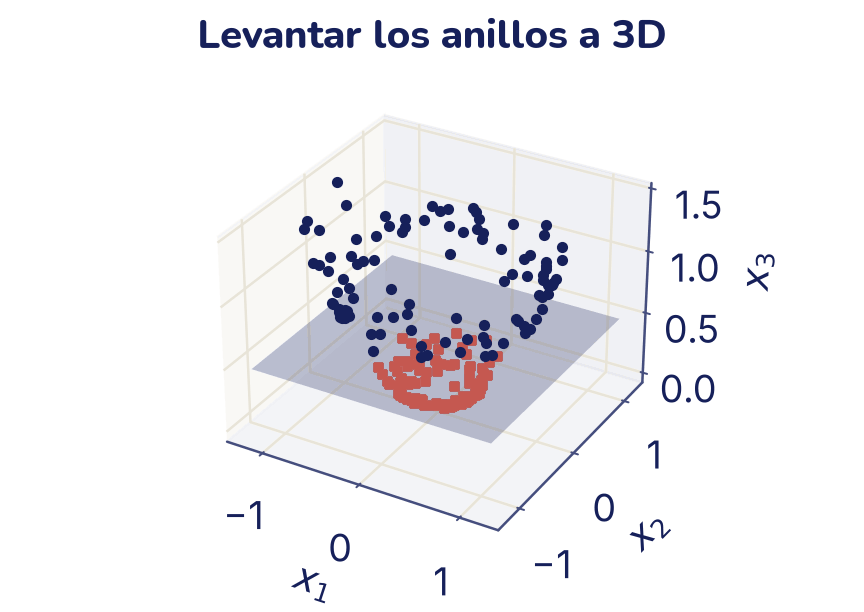

In [ ]:
from sklearn.datasets import make_circles
from sklearn.svm import LinearSVC

# 200 puntos sintéticos: la clase 1 es el anillo de adentro
X_circ, y_circ = make_circles(n_samples=200, factor=0.4, noise=0.08,
                              random_state=0)
# Levantamos cada punto: la altura es su distancia al cuadrado al centro
x3 = X_circ[:, 0] ** 2 + X_circ[:, 1] ** 2
X_3d = np.column_stack([X_circ, x3])

plano = LinearSVC().fit(X_circ, y_circ)
espacio = LinearSVC().fit(X_3d, y_circ)
print(f"Recta en el plano:     aciertos {plano.score(X_circ, y_circ):.2f}")
print(f"Plano en 3D:           aciertos {espacio.score(X_3d, y_circ):.2f}")
print(f"Altura de la clase 1:  hasta {x3[y_circ == 1].max():.2f}")
print(f"Altura de la clase 0:  desde {x3[y_circ == 0].min():.2f}")

fig = plt.figure()
eje = fig.add_subplot(projection="3d")
for clase, color, marca in [(0, "C0", "o"), (1, "C1", "s")]:
    m = y_circ == clase
    eje.scatter(X_circ[m, 0], X_circ[m, 1], x3[m], color=color,
                marker=marca, s=12, depthshade=False)
# Un plano horizontal a media altura separa las dos clases
A, B = np.meshgrid(np.linspace(-1.2, 1.2, 2), np.linspace(-1.2, 1.2, 2))
eje.plot_surface(A, B, np.full_like(A, 0.48), color="C2", alpha=0.3)
eje.set_xlabel("$x_1$")
eje.set_ylabel("$x_2$")
eje.set_zlabel("$x_3$")
eje.set_title("Levantar los anillos a 3D")
plt.show()

En el plano, la mejor recta acierta la mitad: lo mismo que tirar una moneda. Al levantar los puntos, los del anillo de adentro quedan abajo (altura hasta 0,34) y los de afuera, arriba (desde 0,62). Un **plano** horizontal los separa a todos, y una SVM lineal lo encuentra. Si vuelves a mirar desde arriba, ese plano corta al dibujo en un **círculo**: una frontera lineal en 3D es una frontera curva en el plano original.

Esa es la idea de fondo: **agregar características nuevas** convierte un problema curvo en uno lineal. El problema es que, para fronteras complicadas, harían falta muchísimas características nuevas. Aquí entra el **truco del kernel**.

### Similitudes en lugar de coordenadas

Se puede demostrar (no lo haremos aquí) que la SVM nunca necesita las coordenadas de los puntos por separado: solo usa los **productos punto** entre pares de puntos, *x*·*x*′ (el tema 3: multiplicar coordenada por coordenada y sumar). Un **kernel** (en español, «núcleo», aunque casi siempre se dice en inglés) es una función *K*(*x*, *x*′) que calcula directamente el producto punto de los puntos **ya levantados**, sin levantarlos nunca. Veámoslo con el kernel *K*(*a*, *c*) = (*a*·*c*)², para dos puntos *a* y *c* de dos coordenadas. Si desarrollamos el cuadrado:

(*a*·*c*)² = (*a*₁*c*₁ + *a*₂*c*₂)² = *a*₁²*c*₁² + 2·*a*₁*a*₂*c*₁*c*₂ + *a*₂²*c*₂²

Esto es un producto punto de tres coordenadas: (*a*₁², √2·*a*₁*a*₂, *a*₂²)·(*c*₁², √2·*c*₁*c*₂, *c*₂²). El 2 del medio se reparte como √2·√2, una mitad para cada punto. Por eso el levantamiento que corresponde a este kernel es φ(*x*) = (*x*₁², √2·*x*₁*x*₂, *x*₂²). Comprobémoslo con números:

In [ ]:
def levantar(p):
    """Tres características nuevas a partir de (x1, x2)."""
    return np.array([p[0] ** 2, np.sqrt(2) * p[0] * p[1], p[1] ** 2])

a = np.array([1.0, 2.0])
c = np.array([3.0, -1.0])
print("Levantando y multiplicando:", round(levantar(a) @ levantar(c), 6))
print("Con el kernel (a·c)²:      ", (a @ c) ** 2)

Levantando y multiplicando: 1.0
Con el kernel (a·c)²:       1.0


Dan lo mismo: el producto punto en el espacio de tres características se calcula con el producto punto original, elevado al cuadrado. Para dos números no ahorra nada, pero con kernels de grado alto o con muchas características el ahorro es enorme. Los tres kernels más usados son:

$$\begin{array}{rl} \text{lineal:} & K ( \mathbf{x} , {\mathbf{x}}^{'} ) = \mathbf{x} \cdot {\mathbf{x}}^{'} \\[0.6em] \text{polinomial:} & K ( \mathbf{x} , {\mathbf{x}}^{'} ) = {( \gamma \, \mathbf{x} \cdot {\mathbf{x}}^{'} + r )}^{d} \\[0.6em] \text{RBF:} & K ( \mathbf{x} , {\mathbf{x}}^{'} ) = {e}^{- \gamma \, {\| \mathbf{x} - {\mathbf{x}}^{'} \|}^{2}} \end{array}$$

El **polinomial** de grado *d* equivale a agregar todos los productos de hasta *d* características. El **RBF** (*radial basis function*, función de base radial; es el que usa `SVC` si no le dices otro) mide **parecido**: vale 1 si los dos puntos coinciden y baja hacia 0 cuando se alejan. Con él, el puntaje de un punto nuevo es una suma de «montañitas», una centrada en cada vector de soporte, que suman hacia su clase. El número **gamma** (γ) decide qué tan angosta es cada montañita: con γ grande, cada vector de soporte solo influye muy cerca de sí mismo.

In [ ]:
for nombre, modelo in [("lineal", SVC(kernel="linear")),
                       ("polinomial, grado 2", SVC(kernel="poly",
                                                   degree=2)),
                       ("RBF", SVC(kernel="rbf"))]:
    modelo.fit(X_circ, y_circ)
    print(f"Kernel {nombre:20s} aciertos {modelo.score(X_circ, y_circ):.2f}")

Kernel lineal               aciertos 0.62
Kernel polinomial, grado 2  aciertos 1.00
Kernel RBF                  aciertos 1.00


El kernel lineal no puede con los anillos. El polinomial de grado 2 incluye *x*₁² y *x*₂², las piezas del levantamiento que hicimos a mano, y el RBF encuentra la forma solo.

### C y gamma juntos

Volvamos a las dos medias lunas del tema 8, con la misma división en entrenamiento y validación. El kernel RBF tiene dos perillas: *C*, cuánto cuesta cada multa, y γ, el alcance de cada vector de soporte.

γ =  0.1, C =   1:  aciertos al entrenar 0.82   en validación 0.83
γ =  0.1, C = 100:  aciertos al entrenar 0.85   en validación 0.88
γ =   10, C =   1:  aciertos al entrenar 0.94   en validación 0.93
γ =   10, C = 100:  aciertos al entrenar 0.98   en validación 0.83


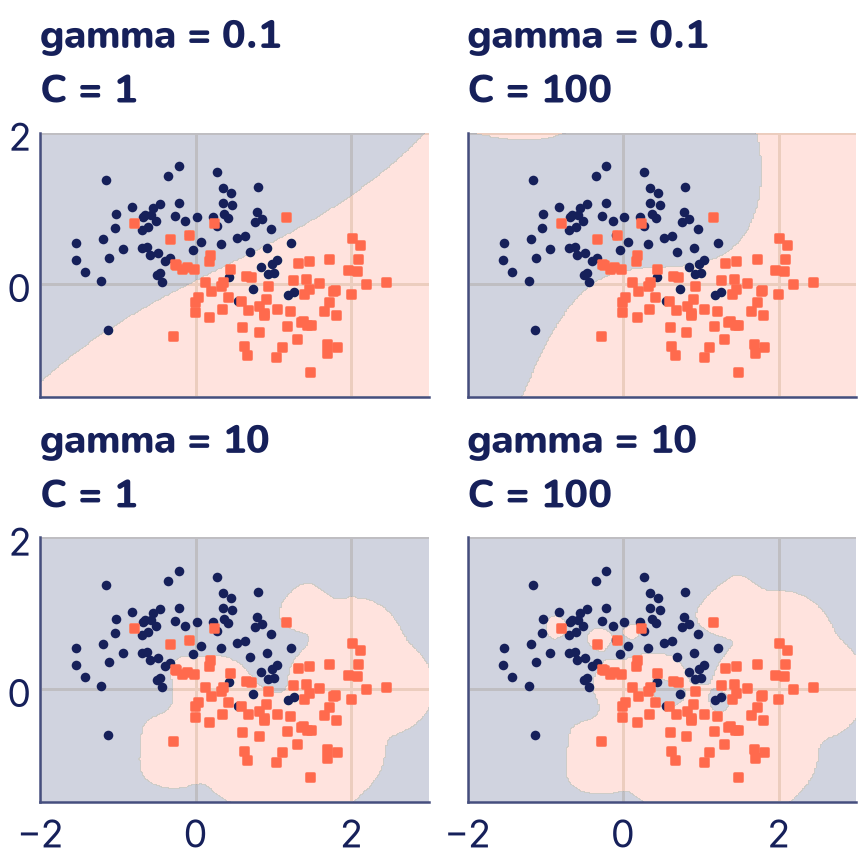

In [ ]:
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split

# Las dos lunas del tema 8, con la misma división
X_lunas, y_lunas = make_moons(n_samples=200, noise=0.3, random_state=0)
X_entr, X_val, y_entr, y_val = train_test_split(
    X_lunas, y_lunas, test_size=0.3, random_state=0)

A, B = np.meshgrid(np.linspace(-2, 3, 200), np.linspace(-1.5, 2, 200))
rejilla = np.column_stack([A.ravel(), B.ravel()])

fig, ejes = plt.subplots(2, 2, figsize=(4.8, 4.8),
                         sharex=True, sharey=True)
for eje, (gamma, C) in zip(ejes.flat,
                           [(0.1, 1), (0.1, 100), (10, 1), (10, 100)]):
    modelo = SVC(kernel="rbf", C=C, gamma=gamma).fit(X_entr, y_entr)
    zona = modelo.predict(rejilla).reshape(A.shape)
    # Cada región, del color de su clase y muy clara
    eje.contourf(A, B, zona, levels=[-0.5, 0.5, 1.5],
                 colors=["C0", "C1"], alpha=0.2)
    dibujar_clases(X_entr, y_entr, ax=eje, s=8)
    eje.set_title(f"gamma = {gamma}\nC = {C}")
    print(f"γ = {gamma:4}, C = {C:3}:  aciertos al entrenar "
          f"{modelo.score(X_entr, y_entr):.2f}"
          f"   en validación {modelo.score(X_val, y_val):.2f}")
plt.show()

- Con **γ = 0,1**, cada vector de soporte influye en una zona enorme y la frontera queda casi recta, o apenas curvada: no logra seguir las lunas. Subir *C* la curva un poco y ayuda algo, pero no alcanza. Es **subajuste**, como la logística del tema 8.
- Con **γ = 10 y *C* = 1**, la frontera se curva con las lunas y le va bien en validación.
- Con **γ = 10 y *C* = 100**, la SVM persigue cada punto: acierta casi todo al entrenar, arma islas alrededor de puntos sueltos y en validación le va peor. Es **sobreajuste**, como k-NN con *k* = 1.

Un γ grande y un *C* grande empujan en la misma dirección: hacia una frontera más complicada.

## Elegir C y gamma con validación cruzada

Como en el tema 10, los hiperparámetros se eligen con `GridSearchCV` sobre un *pipeline* que incluye el escalador. *C* y γ se prueban en escala logarítmica (0,1, 1, 10, 100), porque lo que importa es su orden de magnitud. Los nombres de los pasos de `make_pipeline` son los de las clases en minúsculas: `svc__C` es el `C` del paso `svc`.

In [ ]:
from sklearn.model_selection import GridSearchCV
import pandas as pd

pipe = make_pipeline(StandardScaler(), SVC(kernel="rbf"))
rejilla_hp = {"svc__C": [0.1, 1, 10, 100],
              "svc__gamma": [0.1, 1, 10, 100]}
busqueda = GridSearchCV(pipe, rejilla_hp, cv=5)
busqueda.fit(X_entr, y_entr)

# La exactitud media de validación cruzada de las 16 combinaciones
tabla = pd.DataFrame(busqueda.cv_results_["params"])
tabla["exactitud"] = busqueda.cv_results_["mean_test_score"]
print(tabla.pivot(index="svc__C", columns="svc__gamma",
                  values="exactitud").round(2))
print("Mejor combinación:", busqueda.best_params_)
print(f"Exactitud en validación cruzada: {busqueda.best_score_:.3f}")
print(f"Exactitud en el conjunto de validación: "
      f"{busqueda.score(X_val, y_val):.3f}")

svc__gamma  0.1    1.0    10.0   100.0
svc__C                                
0.1          0.82   0.84   0.51   0.51
1.0          0.83   0.87   0.86   0.69
10.0         0.84   0.89   0.82   0.71
100.0        0.85   0.86   0.83   0.70
Mejor combinación: {'svc__C': 10, 'svc__gamma': 1}
Exactitud en validación cruzada: 0.886
Exactitud en el conjunto de validación: 0.950


Las peores casillas tienen γ grande. Con γ = 100, cada vector de soporte solo ve su vecindad inmediata y la exactitud cae a 0,7 o menos. Con γ = 10 o 100 y *C* = 0,1, el modelo casi no aprende y acierta la mitad, lo mismo que tirar una moneda. En la columna de γ = 0,1 la frontera es demasiado simple y se queda entre 0,82 y 0,85. La mejor combinación, *C* = 10 y γ = 1, llega a 0,886 en validación cruzada y a 0,95 en el conjunto de validación (que tiene solo 60 puntos: cada punto vale 1,7 %, así que esa diferencia es de pocos puntos). Entre las casillas buenas las diferencias son de uno o dos puntos, del mismo tamaño que el vaivén entre pliegues: no te tomes al pie de la letra cuál ganó. La SVM con kernel RBF le gana en validación a la logística del tema 8 (0,85), que solo puede trazar una recta.

## Muchos datos: LinearSVC frente a SVC

`SVC` trabaja con el kernel entre **pares** de puntos. Con *n* ejemplos hay del orden de *n*² pares, así que duplicar los datos hace el entrenamiento al menos cuatro veces más lento (en la práctica, a veces más). Con cientos de miles de ejemplos se vuelve impracticable. Si una frontera lineal alcanza, `LinearSVC` resuelve el mismo tipo de problema con un método pensado para el caso lineal, que crece más o menos en proporción a *n*. Comparemos con 5000 ejemplos sintéticos de 20 características:

In [ ]:
import time
from sklearn.datasets import make_classification

X_grande, y_grande = make_classification(n_samples=5000, n_features=20,
                                         random_state=0)
inicio = time.perf_counter()
lento = SVC(kernel="linear").fit(X_grande, y_grande)
t_svc = time.perf_counter() - inicio

inicio = time.perf_counter()
rapido = LinearSVC().fit(X_grande, y_grande)
t_lineal = time.perf_counter() - inicio

print(f"SVC:       aciertos {lento.score(X_grande, y_grande):.3f}"
      f"   vectores de soporte {len(lento.support_)}")
print(f"LinearSVC: aciertos {rapido.score(X_grande, y_grande):.3f}")
print("¿LinearSVC fue más de 10 veces más rápido?", t_svc > 10 * t_lineal)

SVC:       aciertos 0.955   vectores de soporte 646
LinearSVC: aciertos 0.954
¿LinearSVC fue más de 10 veces más rápido? True


Aciertan lo mismo, pero `LinearSVC` termina muchísimo antes. (No imprimimos los segundos porque cambian de una computadora a otra; en Colab vas a ver la diferencia.) Fíjate además en cuántos vectores de soporte hay: 646 de 5000. Con datos que se mezclan, muchos ejemplos quedan dentro de la calle, y `SVC` tiene que guardarlos todos para predecir. La regla práctica: con pocos miles de ejemplos, `SVC` con kernel RBF es una excelente opción; con muchos más, `LinearSVC` o, si la frontera tiene que ser curva, un bosque o una red neuronal.

## Lo que aprendiste y lo que sigue

- Una **SVM** elige, entre todas las fronteras que separan las clases, la que deja la **calle más ancha**. El ancho de la calle es 2/‖*w*‖, así que una calle ancha significa pesos chicos.
- Los **vectores de soporte** son los puntos que tocan la calle o se meten en ella. Solo ellos definen la frontera: los demás se pueden mover o borrar sin cambiar nada.
- La **pérdida bisagra**, max(0, 1 − *y*·*z*), vale cero para los puntos bien ubicados fuera de la calle. La entropía cruzada nunca llega a cero, por eso en la logística todos los puntos influyen.
- El **margen suave** suma ½‖*w*‖² y *C* veces las multas. Con *C* grande la SVM persigue cada punto (**sobreajuste**); con *C* chico abre la calle y tolera errores (**subajuste** si se pasa).
- Se puede entrenar con **descenso de subgradiente**: el mismo bucle del tema 6, eligiendo una pendiente en la esquina de la bisagra.
- Hay que **escalar** las características, siempre dentro de un *pipeline*.
- El **truco del kernel** da fronteras curvas: levantar los datos a más dimensiones vuelve lineal un problema curvo, y el kernel calcula los productos punto de los puntos levantados sin construirlos. El **RBF** tiene un γ que controla el alcance de cada vector de soporte; *C* y γ se eligen con **validación cruzada**.
- `SVC` se vuelve lento con muchos ejemplos; `LinearSVC` escala mucho mejor si una frontera lineal alcanza.

En el próximo tema los datos traen algo nuevo: un **orden en el tiempo**, que cambia cómo se divide en entrenamiento y validación. Y en la fase 4 vas a ver otra forma de conseguir fronteras curvas: en lugar de elegir un kernel, una red neuronal **aprende** sus propias características.

# Ejercicios

## Antes de empezar

Varios ejercicios usan las variables y funciones de la teoría: `X`, `y`, `signo` (los 40 puntos de dos clases), `dibujar_clases`, `objetivo`, `svm_subgradiente`, `dibujar_svm`, y las importaciones de scikit-learn (`SVC`, `LinearSVC`, `make_pipeline`, `StandardScaler`, `GridSearchCV`, `cross_val_score`). En este cuaderno, ejecuta las celdas de la teoría y trabaja en los ejercicios, que vienen debajo. Intenta cada ejercicio antes de abrir la respuesta.

## Ejercicios

### 1. ¿Quiénes sostienen la calle?

Ocho puntos en el plano. Clase 0: (0, 0), (1, 0), (0, 1) y (−1, −1). Clase 1: (3, 3), (2, 3), (3, 2) y (4, 4).

a) Dibújalos en papel. Sin calcular nada, ¿cuál crees que es la frontera de margen máximo? ¿Qué puntos serán los vectores de soporte?

b) ¿Cuánto mide el ancho de la calle?

c) Si borras los puntos (−1, −1) y (4, 4), ¿cambia la frontera? Comprueba todo con `SVC(kernel="linear", C=1000)`: un *C* tan grande se comporta como el margen duro.

<details>
<summary>Respuesta</summary>

a) Los puntos más cercanos entre las dos clases son (1, 0) y (0, 1) de un lado, y (3, 2) y (2, 3) del otro. Los dos primeros están sobre la recta *x*₁ + *x*₂ = 1 y los otros dos sobre *x*₁ + *x*₂ = 5. La frontera va justo por el medio, paralela a ellas: *x*₁ + *x*₂ = 3. Esos cuatro puntos tocan los bordes de la calle: son los candidatos a **vectores de soporte** (abajo verás por qué la lista puede ser más corta).

b) La calle va de *x*₁ + *x*₂ = 1 a *x*₁ + *x*₂ = 5. La distancia entre esas dos rectas es 4/√2 ≈ **2,83**. Con la fórmula del tema: la frontera *x*₁ + *x*₂ − 3 = 0 escrita con la convención de la SVM (puntaje ±1 en los vectores de soporte) es 0,5·*x*₁ + 0,5·*x*₂ − 1,5 = 0, y 2/‖*w*‖ = 2/√0,5 ≈ 2,83.

Los cuatro puntos que elegimos tienen *y*·*z* = 1: tocan los bordes de la calle. scikit-learn reporta solo dos de ellos como vectores de soporte porque, al estar alineados sobre los bordes, dos bastan para fijar la calle. Cuando pasa esto, la lista de vectores de soporte no es única: cualquier elección que fije la misma calle sirve, y la frontera es la misma. Con datos reales, con ruido, casi nunca hay puntos tan perfectamente alineados.

c) No cambia: (−1, −1) y (4, 4) están lejos de la calle y no son vectores de soporte.

</details>

In [ ]:
# @title Respuesta: código (doble clic para verlo)
X1 = np.array([[0, 0], [1, 0], [0, 1], [-1, -1],
               [3, 3], [2, 3], [3, 2], [4, 4]])
y1 = np.array([0, 0, 0, 0, 1, 1, 1, 1])

duro = SVC(kernel="linear", C=1000).fit(X1, y1)
w1, b1 = duro.coef_[0], duro.intercept_[0]
print("w =", np.round(w1, 3), "  b =", round(b1, 3))
# decision_function da el puntaje z de cada punto
print("y·z de cada punto:", np.round(np.where(y1 == 1, 1, -1)
                                    * duro.decision_function(X1), 2))
print("Vectores de soporte que reporta scikit-learn:",
      duro.support_vectors_.tolist())
print(f"Ancho de la calle: {2 / np.linalg.norm(w1):.2f}")

# Sin los dos puntos lejanos (índices 3 y 7)
quedan = [0, 1, 2, 4, 5, 6]
sin_lejanos = SVC(kernel="linear", C=1000).fit(X1[quedan], y1[quedan])
print("Sin los lejanos: w =", np.round(sin_lejanos.coef_[0], 3),
      "  b =", round(sin_lejanos.intercept_[0], 3))

### 2. Multas a mano

Una SVM tiene *w* = (2, 0) y *b* = −2, y estos cuatro puntos con sus clases como signos:

| Punto | (*x*₁, *x*₂) | Clase |
|---|---|---|
| P | (0, 1) | −1 |
| Q | (1,2; 0) | +1 |
| R | (0,8; 2) | +1 |
| S | (3, −1) | +1 |

a) ¿Dónde está la frontera? ¿Dónde están los bordes de la calle y cuánto mide de ancho?

b) Para cada punto, calcula *z*, *y*·*z* y su pérdida bisagra. ¿Cuál está fuera de la calle, cuál dentro y cuál del lado equivocado?

c) Calcula el objetivo *J* con *C* = 1. Compruébalo con la función `objetivo` de la teoría.

<details>
<summary>Respuesta</summary>

a) *z* = 2·*x*₁ − 2, así que la frontera es la recta vertical *x*₁ = 1. Los bordes, donde *z* = ±1, son *x*₁ = 0,5 y *x*₁ = 1,5. El ancho es 2/‖*w*‖ = 2/2 = **1**, que coincide con 1,5 − 0,5.

b)

| Punto | *z* | *y*·*z* | Bisagra | Dónde está |
|---|---|---|---|---|
| P | −2 | 2 | 0 | fuera de la calle, lado correcto |
| Q | 0,4 | 0,4 | 0,6 | dentro de la calle, lado correcto |
| R | −0,4 | −0,4 | 1,4 | lado equivocado |
| S | 4 | 4 | 0 | fuera de la calle, lado correcto |

c) *J* = ½·(2² + 0²) + 1·(0 + 0,6 + 1,4 + 0) = 2 + 2 = **4**.

</details>

In [ ]:
# @title Respuesta: código (doble clic para verlo)
X2 = np.array([[0, 1], [1.2, 0], [0.8, 2], [3, -1]])
s2 = np.array([-1, 1, 1, 1])
w2, b2 = np.array([2.0, 0.0]), -2.0

z = X2 @ w2 + b2
print("z:      ", np.round(z, 2))
print("y·z:    ", np.round(s2 * z, 2))
print("bisagra:", np.round(np.maximum(0, 1 - s2 * z), 2))
print("J =", round(objetivo(X2, s2, w2, b2, C=1), 2))

### 3. El primer paso de subgradiente

Con los cuatro puntos del ejercicio 2, empieza en *w* = (0, 0) y *b* = 0, con *C* = 1 y tasa α = 0,1.

a) ¿Qué puntos pagan multa en el punto de partida? ¿Por qué?

b) Calcula a mano ∂*J*/∂*w* y ∂*J*/∂*b*, y da un paso. ¿Cuáles son los nuevos *w* y *b*?

c) Compruébalo con `svm_subgradiente(..., pasos=1)`. ¿Bajó el objetivo?

<details>
<summary>Respuesta</summary>

a) Todos: con *w* = 0 y *b* = 0, todos los puntajes son 0, así que *y*·*z* = 0, que es menor que 1. Cada uno paga una multa de 1 y *J* = 0 + 4 = 4.

b) Como *w* = 0, el primer término no aporta y queda −*C* por la suma de *y*ᵢ·*x*ᵢ de los cuatro puntos:

- Σ *y*ᵢ·*x*ᵢ = −(0, 1) + (1,2; 0) + (0,8; 2) + (3, −1) = (5, 0), así que ∂*J*/∂*w* = **(−5, 0)**.
- Σ *y*ᵢ = −1 + 1 + 1 + 1 = 2, así que ∂*J*/∂*b* = **−2**.

El paso: *w* = (0, 0) − 0,1·(−5, 0) = **(0,5; 0)** y *b* = 0 − 0,1·(−2) = **0,2**. La frontera nueva es vertical, en *x*₁ = −0,4: los puntos de la clase +1 tienen *x*₁ grande y el paso los empujó hacia su lado.

c)

</details>

In [ ]:
# @title Respuesta: código (doble clic para verlo)
w_paso, b_paso, h = svm_subgradiente(X2, s2, C=1, tasa=0.1, pasos=1)
print("w =", w_paso, "  b =", round(b_paso, 2))
print(f"J antes = {h[0]:.2f}"
      f"   después = {objetivo(X2, s2, w_paso, b_paso, C=1):.3f}")

<details>
<summary>Respuesta (sigue)</summary>

Sí bajó, de 4 a 1,925, con un solo paso.

</details>

### 4. Un punto lejano: SVM frente a logística

Agrega a los 40 puntos de la teoría un círculo de la clase 0 en (−1,2; −0,8): del lado correcto y fuera de la calle de la SVM. Entrena una SVM lineal (`SVC(kernel="linear", C=1)`) y una regresión logística (`LogisticRegression()`) con y sin ese punto. ¿Cuál de los dos modelos cambia? Explica por qué con la forma de sus pérdidas.

In [ ]:
# @title Respuesta: código (doble clic para verlo)
from sklearn.linear_model import LogisticRegression

X_lejos = np.vstack([X, [[-1.2, -0.8]]])
y_lejos = np.append(y, 0)

for nombre, Modelo, opciones in [("SVM", SVC, {"kernel": "linear"}),
                                 ("Logística", LogisticRegression, {})]:
    antes = Modelo(**opciones).fit(X, y)
    despues = Modelo(**opciones).fit(X_lejos, y_lejos)
    print(f"{nombre}:  sin el punto w = {np.round(antes.coef_[0], 3)},"
          f" b = {antes.intercept_[0]:.3f}")
    print(f"{nombre}:  con el punto w = {np.round(despues.coef_[0], 3)},"
          f" b = {despues.intercept_[0]:.3f}")

<details>
<summary>Respuesta</summary>

La SVM no cambia nada: el punto nuevo está del lado correcto y fuera de la calle, así que su pérdida bisagra es cero y su subgradiente también. No es un vector de soporte. La logística sí cambia, poco pero cambia: la entropía cruzada nunca llega a cero, así que hasta un punto bien clasificado sigue empujando los pesos (cuanto más lejos está, menos empuja, pero nunca deja de hacerlo). Es la diferencia que viste en la figura de la bisagra: en la SVM solo unos pocos puntos deciden la frontera; en la logística opinan todos.

</details>

### 5. Buscar C y gamma

Usa el conjunto de datos de tumores de mama (`load_breast_cancer`, incluido en scikit-learn; lo conoces del tema 8). Separa un 25 % para prueba con `random_state=0` y `stratify=y`. Con el resto, busca *C* y γ de una SVM con kernel RBF con `GridSearchCV` y validación cruzada de 5 pliegues, probando 0,1, 1, 10 y 100 para *C* y 0,001, 0,01, 0,1 y 1 para γ. No olvides escalar dentro del *pipeline*.

a) ¿Cuál es la mejor combinación y su exactitud en validación cruzada? ¿Y en prueba?

b) Pide también la exactitud de entrenamiento (`return_train_score=True`) y compárala con la de validación cruzada en la combinación con *C* y γ más grandes. ¿Qué pasa ahí?

In [ ]:
# @title Respuesta: código (doble clic para verlo)
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split

Xc, yc = load_breast_cancer(return_X_y=True)
Xc_ent, Xc_prueba, yc_ent, yc_prueba = train_test_split(
    Xc, yc, test_size=0.25, random_state=0, stratify=yc)

pipe_c = make_pipeline(StandardScaler(), SVC(kernel="rbf"))
rejilla_c = {"svc__C": [0.1, 1, 10, 100],
             "svc__gamma": [0.001, 0.01, 0.1, 1]}
busqueda_c = GridSearchCV(pipe_c, rejilla_c, cv=5,
                          return_train_score=True)
busqueda_c.fit(Xc_ent, yc_ent)
print("Mejor combinación:", busqueda_c.best_params_)
print(f"Validación cruzada: {busqueda_c.best_score_:.3f}"
      f"   prueba: {busqueda_c.score(Xc_prueba, yc_prueba):.3f}")

# La última combinación de la rejilla: C = 100 y gamma = 1
res = busqueda_c.cv_results_
print(f"C = 100, gamma = 1:  entrenamiento "
      f"{res['mean_train_score'][-1]:.3f}"
      f"   validación cruzada {res['mean_test_score'][-1]:.3f}")

<details>
<summary>Respuesta</summary>

a) La mejor combinación es *C* = 100 y γ = 0,001, con 0,988 en validación cruzada y 0,958 en prueba. Fíjate en que quedó en un **borde** de la rejilla (el *C* más grande y el γ más chico que probamos): conviene ampliar la rejilla hacia ese lado y buscar de nuevo, porque el mejor valor podría estar afuera. La prueba da algo menos que la validación cruzada; es normal, porque el mejor puntaje de una búsqueda es un poco optimista (tema 10).

b) Con *C* = 100 y γ = 1, el modelo acierta el 100 % de los datos con que entrena, pero en validación cruzada le va mucho peor: **sobreajuste**. Con 30 características estandarizadas, γ = 1 hace que cada vector de soporte solo influya en su vecindad inmediata, y *C* grande no perdona errores: el modelo memoriza. La exactitud de prueba se mide **una sola vez**, al final, con la combinación ya elegida.

</details>

### 6. Levantar una sola variable

Trece puntos sobre una recta, *x* = −3, −2,5, …, 3. Son de la clase 1 los que cumplen −1,2 ≤ *x* ≤ 1,2, y de la clase 0 los demás.

a) ¿Puede una SVM lineal con la sola característica *x* separar las clases? (Con una variable, la frontera es un solo umbral.)

b) Levanta los datos agregando la característica *x*². ¿Ahora sí? ¿Qué frontera en *x* corresponde a la recta que encuentra la SVM en el plano (*x*, *x*²)?

<details>
<summary>Respuesta</summary>

a) No: la mejor SVM con solo *x* acierta 0,62 (8 de 13 puntos). Con una variable, un modelo lineal predice una clase a un lado de un umbral y la otra al otro lado. Pero la clase 1 está en el medio y la clase 0 en los dos extremos: ningún umbral solo puede separarlas.

b) Sí. Con *x*², los puntos del medio quedan abajo (*x*² chico) y los de los extremos arriba: una recta en el plano (*x*, *x*²) los separa. Esa recta, vuelta a la variable original, son **dos umbrales**, uno a cada lado del cero.

</details>

In [ ]:
# @title Respuesta: código (doble clic para verlo)
x = np.linspace(-3, 3, 13)
clase = (np.abs(x) <= 1.2).astype(int)

solo_x = LinearSVC().fit(x.reshape(-1, 1), clase)
print(f"Solo x:     aciertos {solo_x.score(x.reshape(-1, 1), clase):.2f}")

X_lev = np.column_stack([x, x ** 2])
levantado = LinearSVC().fit(X_lev, clase)
print(f"Con x y x²: aciertos {levantado.score(X_lev, clase):.2f}")

# La frontera w1·x + w2·x² + b = 0 es una ecuación de segundo grado
w_a, w_b = levantado.coef_[0]
print("Umbrales en x:",
      np.round(np.sort(np.roots([w_b, w_a, levantado.intercept_[0]])), 2))

<details>
<summary>Respuesta (sigue)</summary>

Es el mismo truco que con los anillos de la teoría, en una dimensión menos: lo que en el espacio levantado es una frontera lineal, en el original es una frontera curva (aquí, dos cortes).

</details>

## Mini-proyecto: dígitos con SVM, logística y bosque

Vas a comparar tres modelos en `load_digits` (incluido en scikit-learn): 1797 imágenes de dígitos escritos a mano, de 8 × 8 píxeles, que viste en el tema 8.

**Pasos.**

1. **Divide.** Separa un 25 % para prueba con `train_test_split(..., test_size=0.25, random_state=0, stratify=y)`.
2. **Tres modelos.** Entrena con los mismos datos de entrenamiento:
   - una SVM con kernel RBF dentro de un *pipeline* con `StandardScaler`;
   - una regresión logística en un *pipeline* igual (con `max_iter=2000`);
   - un `RandomForestClassifier(random_state=0)` (tema 11), sin escalar: a los árboles no les importa la escala.
3. **Mide.** Para cada uno, la exactitud en prueba y el tiempo de entrenar y de predecir, con `time.perf_counter()`.
4. **Ajusta la SVM.** Busca *C* y γ con `GridSearchCV` sobre los datos de entrenamiento. ¿Mejora en prueba?
5. **Mira los vectores de soporte.** ¿Cuántos de los ejemplos de entrenamiento son vectores de soporte en la SVM ajustada?
6. **Concluye.** Escribe tres conclusiones de una o dos frases. Por ejemplo: ¿cuál conviene si importa la exactitud? ¿Y si importa la velocidad para predecir? ¿Qué pasaría con la SVM si tuvieras un millón de imágenes?

<details>
<summary>Resultados de referencia, para comprobar los tuyos</summary>

Este código hace los pasos 1 a 5. Los tiempos cambian de una computadora a otra, así que solo se comparan.

</details>

In [ ]:
# @title Resultados de referencia, para comprobar los tuyos: código (doble clic para verlo)
import time
from sklearn.datasets import load_digits
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

Xd, yd = load_digits(return_X_y=True)
Xd_ent, Xd_prueba, yd_ent, yd_prueba = train_test_split(
    Xd, yd, test_size=0.25, random_state=0, stratify=yd)

modelos = {
    "SVM (RBF)": make_pipeline(StandardScaler(), SVC()),
    "Logística": make_pipeline(StandardScaler(),
                               LogisticRegression(max_iter=2000)),
    "Bosque": RandomForestClassifier(random_state=0),
}
tiempos = {}
for nombre, modelo in modelos.items():
    inicio = time.perf_counter()
    modelo.fit(Xd_ent, yd_ent)
    medio = time.perf_counter()
    exactitud = modelo.score(Xd_prueba, yd_prueba)
    fin = time.perf_counter()
    tiempos[nombre] = (medio - inicio, fin - medio)
    print(f"{nombre:10s} exactitud en prueba {exactitud:.3f}")

print("¿La logística predice más rápido que la SVM?",
      tiempos["Logística"][1] < tiempos["SVM (RBF)"][1])

rejilla_d = {"svc__C": [1, 10, 100],
             "svc__gamma": [0.001, 0.01, 0.1]}
busqueda_d = GridSearchCV(make_pipeline(StandardScaler(), SVC()),
                          rejilla_d, cv=5)
busqueda_d.fit(Xd_ent, yd_ent)
print("Mejor combinación:", busqueda_d.best_params_)
print(f"Validación cruzada: {busqueda_d.best_score_:.3f}"
      f"   prueba: {busqueda_d.score(Xd_prueba, yd_prueba):.3f}")
mejor_svc = busqueda_d.best_estimator_[-1]
print("Vectores de soporte:", len(mejor_svc.support_), "de", len(yd_ent))

<details>
<summary>Resultados de referencia, para comprobar los tuyos (sigue)</summary>

- Los tres modelos aciertan entre el 97 % y el 98 % de los dígitos de prueba. La SVM (0,982) y el bosque (0,980) quedan prácticamente empatados; la logística, un poco atrás (0,969). Con 450 imágenes de prueba, una diferencia de 0,002 es una sola imagen: no alcanza para declarar un ganador.
- Ajustar *C* y γ no mejoró la prueba (0,980 frente a 0,982 con los valores por defecto): los valores por defecto de `SVC` ya eran buenos para estos datos, y la diferencia es otra vez de una imagen.
- La SVM ajustada usa 619 de los 1347 ejemplos de entrenamiento como vectores de soporte, y para predecir tiene que comparar cada imagen nueva con todos ellos. Por eso la logística, que solo hace una multiplicación por sus pesos, predice más rápido. Con un millón de imágenes, entrenar `SVC` sería lentísimo: ahí convienen `LinearSVC`, la logística o una red neuronal.

</details>

## Errores comunes

- **No escalar.** La SVM mide distancias: sin estandarizar, la característica con números más grandes manda sola. El escalador va dentro del *pipeline*, para que se ajuste solo con los datos de entrenamiento de cada pliegue.
- **Usar las clases 0 y 1 en la bisagra.** La fórmula max(0, 1 − *y*·*z*) supone clases −1 y +1. Con *y* = 0 la multa vale siempre 1, sin importar el puntaje. (scikit-learn hace la conversión por su cuenta; tu código, no.)
- **Leer *C* al revés.** En las SVM (y en `LogisticRegression`), *C* grande significa **poca** regularización: calle angosta, riesgo de sobreajuste. Es lo contrario del α de Ridge.
- **Probar *C* y γ en escala lineal.** Lo que importa es el orden de magnitud: prueba 0,01, 0,1, 1, 10, 100, no 1, 2, 3, 4.
- **Elegir hiperparámetros mirando el conjunto de prueba.** Se eligen con validación cruzada sobre el entrenamiento; la prueba se usa una sola vez, al final.
- **Usar `SVC` con cientos de miles de ejemplos.** Su costo crece mucho más rápido que la cantidad de datos. Si una frontera lineal alcanza, usa `LinearSVC`.
- **Esperar probabilidades.** Una SVM da un puntaje (`decision_function`), no una probabilidad. `SVC(probability=True)` las estima con un paso extra, más lento y no siempre bien calibrado; si necesitas probabilidades confiables, la logística es más directa.
- **Creer que el kernel es magia.** Un kernel RBF con γ demasiado grande memoriza los datos igual que k-NN con *k* = 1. La validación cruzada es la que dice si la curva ayuda.

## ¿Lo lograste?

Al terminar este tema deberías poder hacer lo siguiente. Al lado, dónde lo practicaste.

- Explicar el margen y los vectores de soporte (ejercicios 1, 2 y 4, y la actividad).
- Explicar el papel de *C* (margen suave) y su relación con el sobreajuste (ejercicios 2 y 5, y la actividad).
- Programar una SVM lineal con descenso de subgradiente sobre la pérdida bisagra (ejercicio 3).
- Explicar el truco del kernel con un ejemplo de levantar los datos a más dimensiones (ejercicio 6).
- Ajustar *C* y γ del kernel RBF con validación cruzada (ejercicio 5 y pasos 4 y 5 del mini-proyecto).